# importing

In [35]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# loading the dataset

In [37]:
df_insurance = pd.read_csv('insurance.csv')
df_insurance

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86
...,...,...,...,...,...,...,...
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95


# Step 1 : EDA

In [38]:
df_insurance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [39]:
df_insurance.describe()

,age,bmi,children,expenses
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.665471,1.094918,13270.422414
std,14.049960,6.098382,1.205493,12110.011240
min,18.000000,16.000000,0.000000,1121.870000
25%,27.000000,26.300000,0.000000,4740.287500
50%,39.000000,30.400000,1.000000,9382.030000
75%,51.000000,34.700000,2.000000,16639.915000
max,64.000000,53.100000,5.000000,63770.430000


<Axes: xlabel='age', ylabel='expenses'>

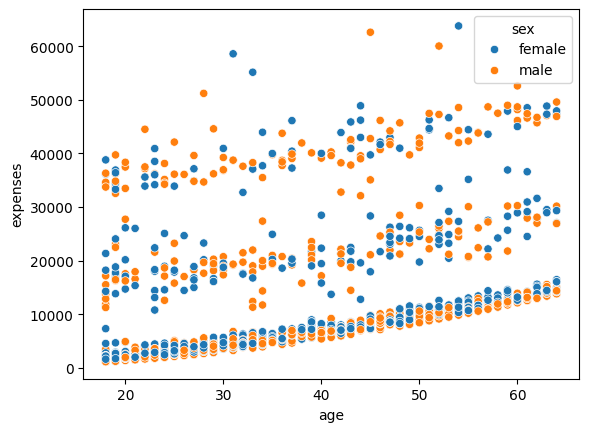

In [40]:
sns.scatterplot(data = df_insurance, x = "age", y = "expenses", hue="sex")

In [41]:
df_insurance

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86
...,...,...,...,...,...,...,...
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95


### we need to convert strings to numerical values for the heatmap 

In [42]:
# LabelEncoder for 'sex', 'smoker' (2 categories) - OK
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df_insurance['sex'] = le.fit_transform(df_insurance['sex'])
df_insurance['smoker'] = le.fit_transform(df_insurance['smoker'])

# For 'region' (4 categories) - Better to use OneHotEncoder
# OneHotEncoder for 'region'
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(drop='first', sparse_output=False)
encoded = ohe.fit_transform(df_insurance[['region']])

In [43]:
# Add encoded columns to dataframe
region_cols = ohe.get_feature_names_out(['region'])
df_encoded = pd.DataFrame(encoded, columns=region_cols, index=df_insurance.index)
df_insurance = pd.concat([df_insurance.drop('region', axis=1), df_encoded], axis=1)
df_insurance

,age,sex,bmi,children,smoker,expenses,region_northwest,region_southeast,region_southwest
0,19,0,27.9,0,1,16884.92,0.0,0.0,1.0
1,18,1,33.8,1,0,1725.55,0.0,1.0,0.0
2,28,1,33.0,3,0,4449.46,0.0,1.0,0.0
3,33,1,22.7,0,0,21984.47,1.0,0.0,0.0
4,32,1,28.9,0,0,3866.86,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
1333,50,1,31.0,3,0,10600.55,1.0,0.0,0.0
1334,18,0,31.9,0,0,2205.98,0.0,0.0,0.0
1335,18,0,36.9,0,0,1629.83,0.0,1.0,0.0
1336,21,0,25.8,0,0,2007.95,0.0,0.0,1.0


In [44]:
df_insurance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1338 non-null   int64  
 1   sex               1338 non-null   int32  
 2   bmi               1338 non-null   float64
 3   children          1338 non-null   int64  
 4   smoker            1338 non-null   int32  
 5   expenses          1338 non-null   float64
 6   region_northwest  1338 non-null   float64
 7   region_southeast  1338 non-null   float64
 8   region_southwest  1338 non-null   float64
dtypes: float64(5), int32(2), int64(2)
memory usage: 83.8 KB


<Axes: >

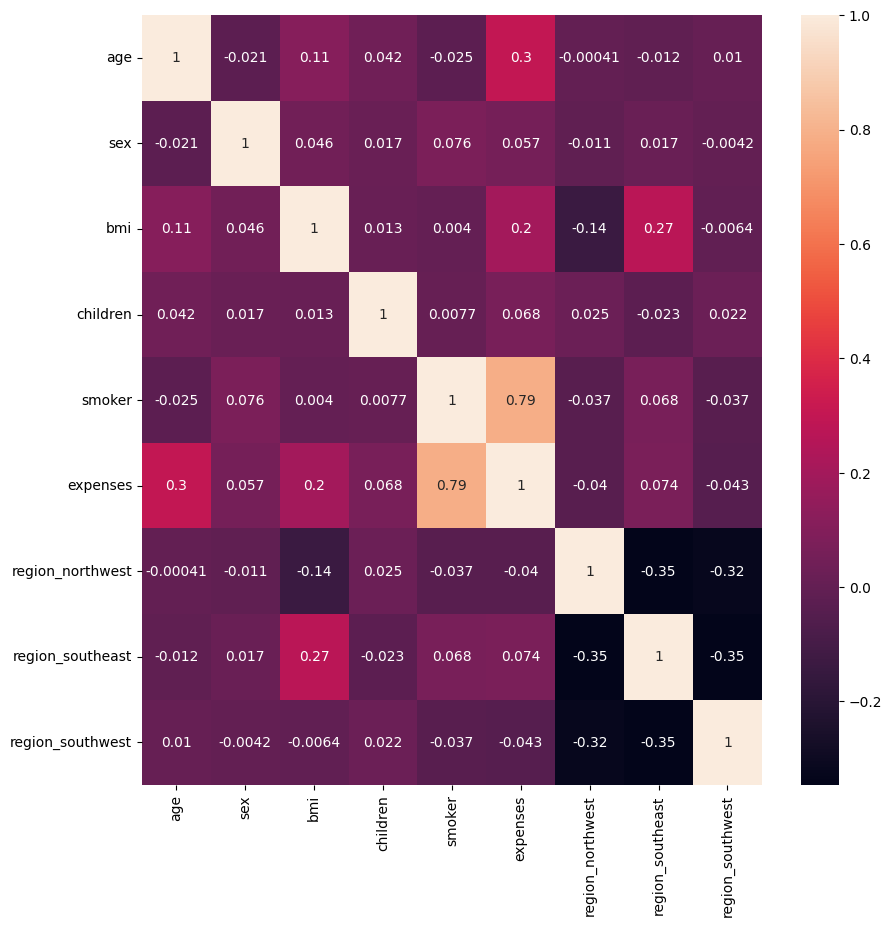

In [45]:
plt.figure(figsize=(10,10))
sns.heatmap(data=df_insurance.corr(), annot=True)

### from the figure we understand that charges have high correlation with if smoker

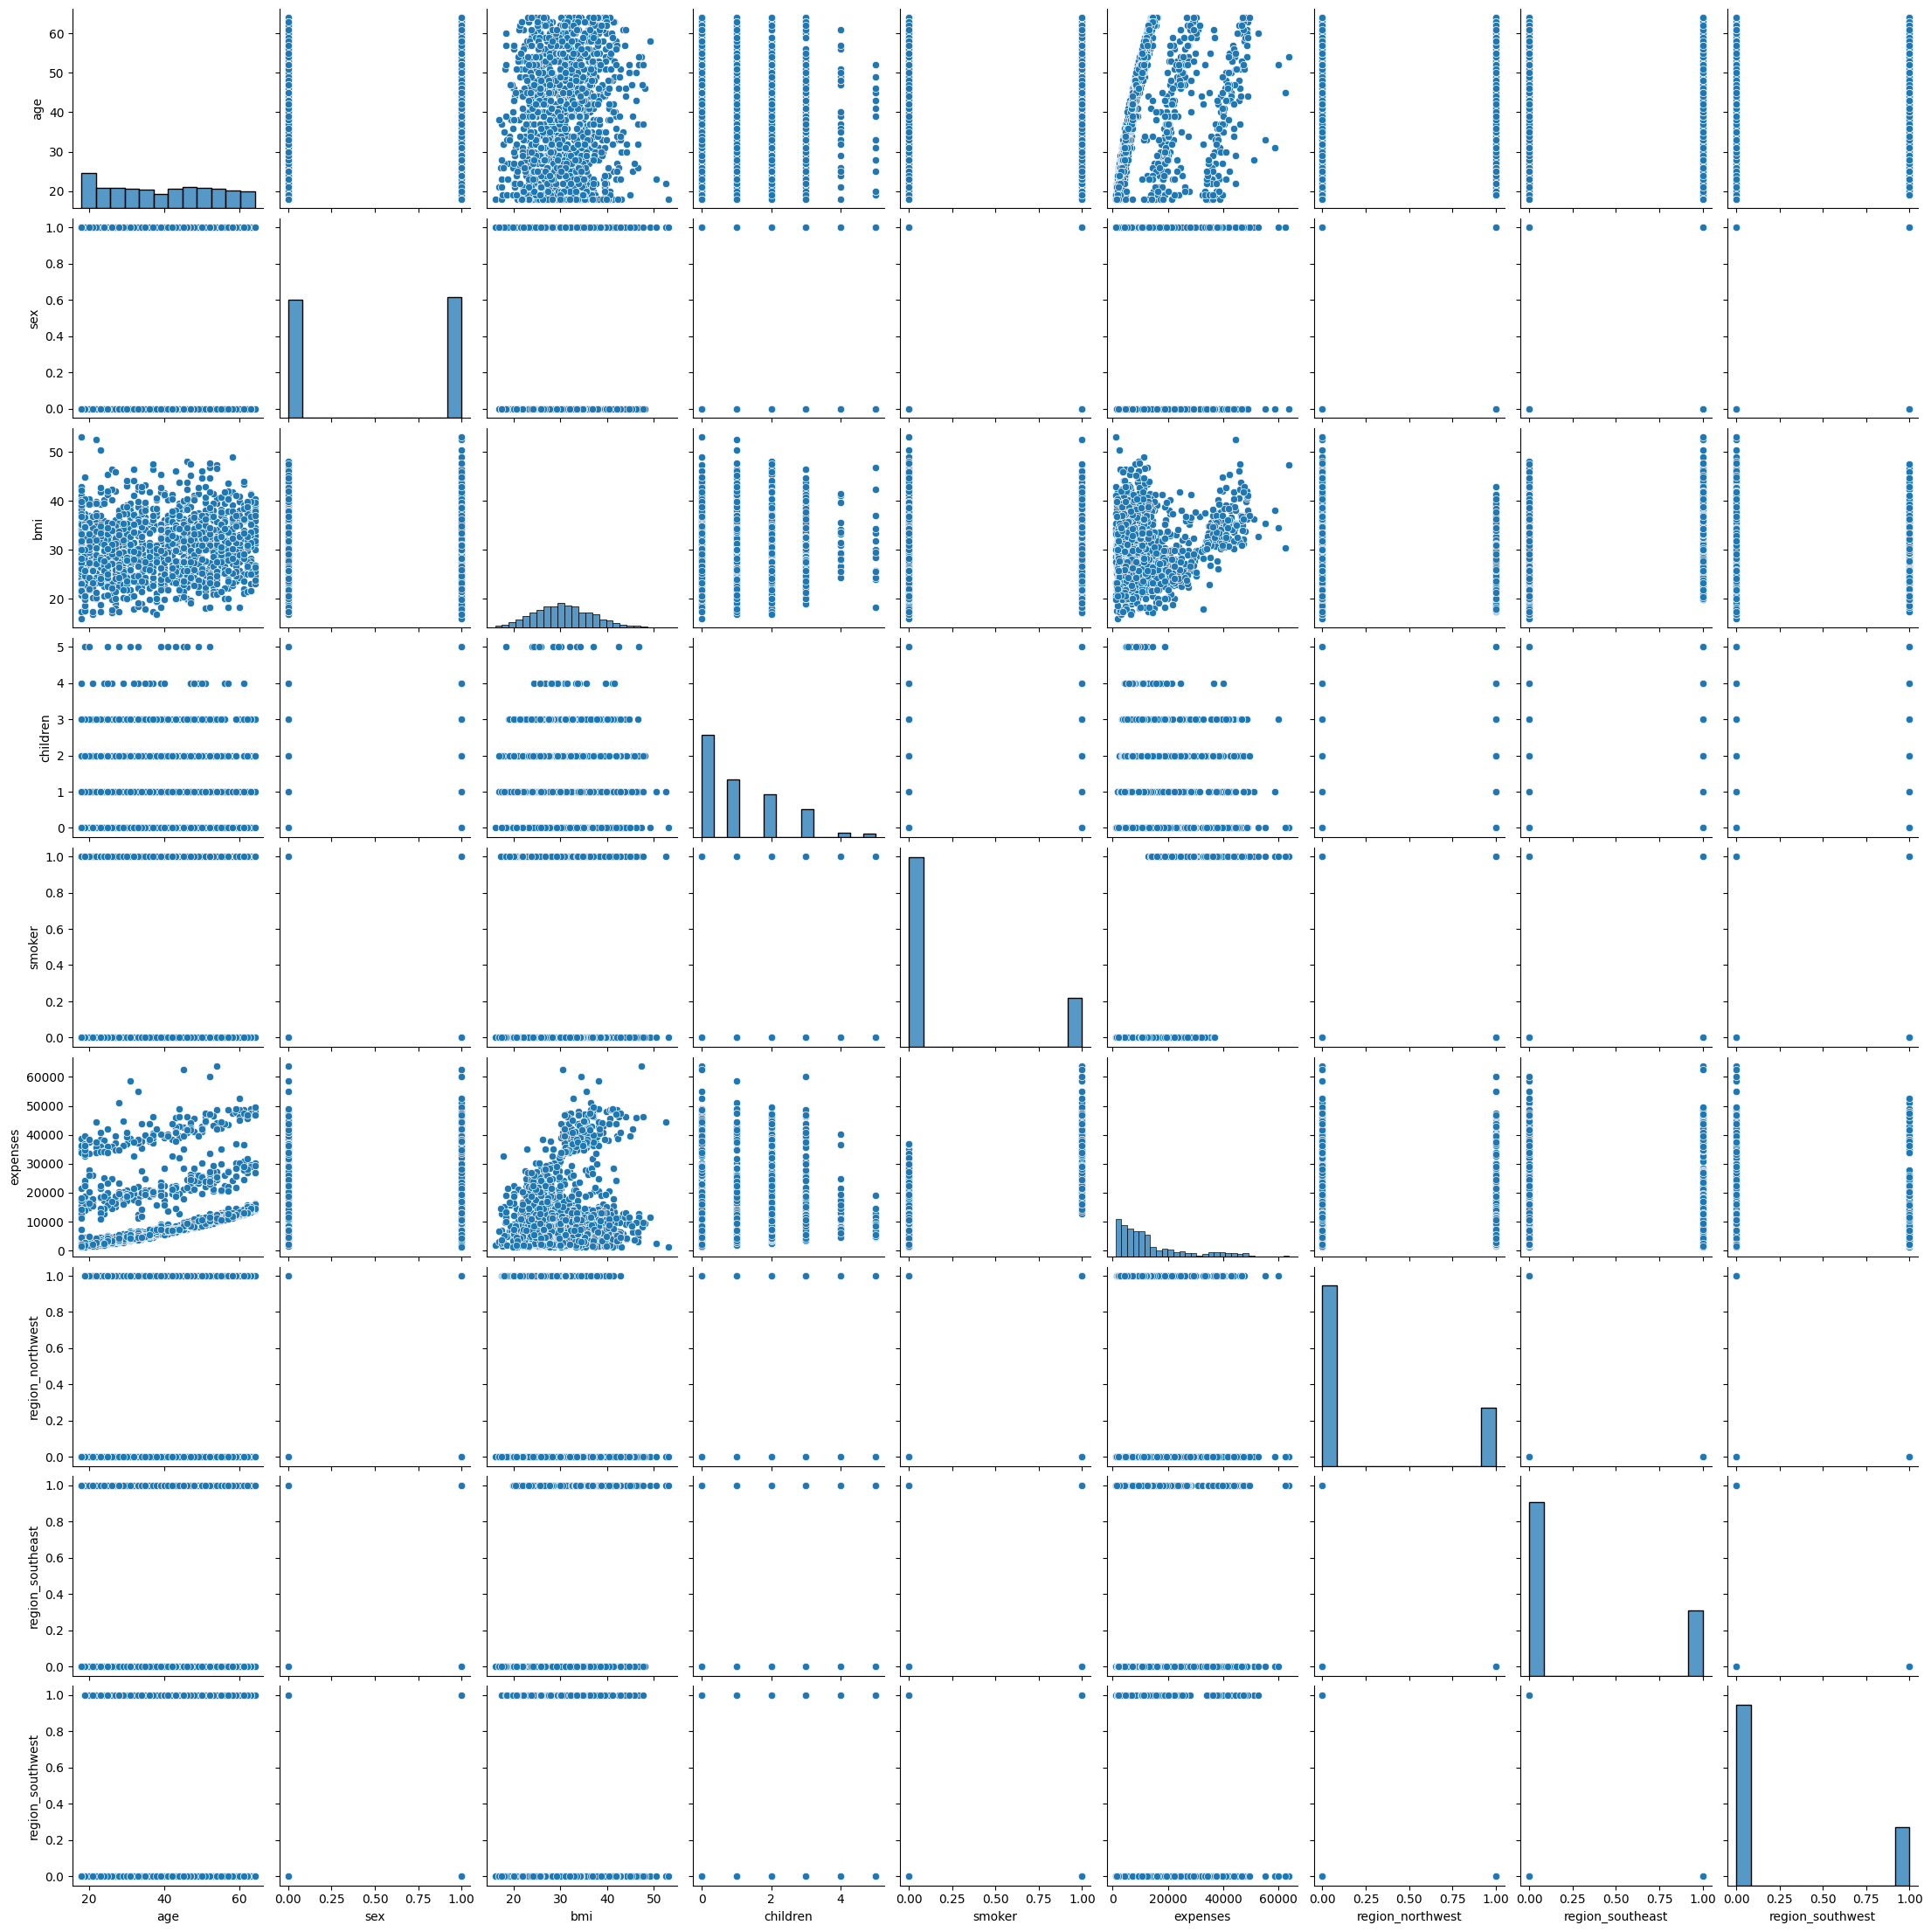

In [46]:
sns.pairplot(df_insurance)

# Step 2 : Splitting  

In [47]:
# axis=1 = columns 
x = df_insurance.drop("expenses" , axis=1)
y = df_insurance["expenses"]

In [48]:
from sklearn.model_selection import train_test_split

In [49]:
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.3, train_size=0.7,random_state=23)

# Step 3 : Model training

In [50]:
from sklearn.linear_model import LinearRegression
lm = LinearRegression()

In [51]:
lm.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


# Step 4 : Testing model 

In [52]:
prediction = lm.predict(x_test)
prediction
# the array that we got should be close to y_test

array([ 1.15545816e+04,  6.42307029e+03,  3.16877581e+04,  1.01018613e+04,
        8.14345046e+03,  9.37319346e+03,  3.57043244e+04,  8.49402080e+03,
        1.28598352e+04,  3.96237457e+04,  1.64148722e+03,  3.70516742e+04,
        4.27779349e+03,  1.23131069e+04,  8.20667740e+03,  5.15397577e+03,
        5.20939756e+03,  3.57811118e+03,  3.53368116e+04,  3.33159642e+04,
        3.90517060e+04,  1.35664019e+04,  8.17943506e+03,  9.76346301e+03,
        3.58471244e+04,  6.93376595e+03,  5.24582520e+03,  2.93737940e+04,
        4.32235490e+02,  1.14017461e+04,  1.37335102e+04,  4.83943564e+03,
        3.84155446e+03,  1.20300763e+04,  8.84610873e+03,  2.91575072e+04,
        1.11763800e+04,  1.06381916e+04,  9.75683456e+03,  4.45920790e+03,
        1.08760861e+04,  3.43201407e+04,  1.12162167e+04,  3.18970520e+04,
        1.11753074e+04,  1.36142101e+04,  4.27753102e+03,  5.47528375e+03,
        8.76569201e+03,  5.33280434e+03,  1.35423290e+04,  8.84514669e+03,
        1.04193497e+04,  

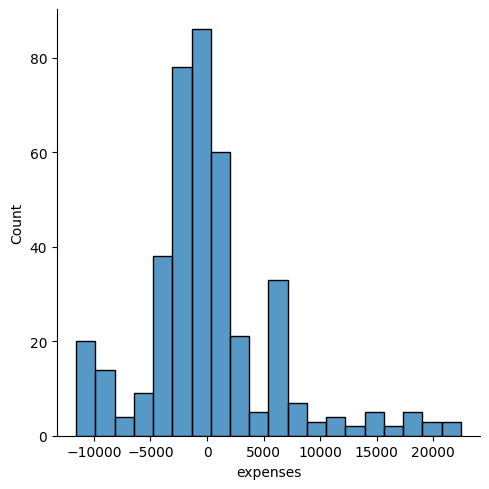

In [53]:
sns.displot(( y_test - prediction ), bins = 20)
## closer to 0 = good model

In [54]:
df_coffetion = pd.DataFrame(lm.coef_, x.columns, columns=["Coff"])
df_coffetion

,Coff
age,245.651176
sex,-172.599770
bmi,351.388362
children,545.451698
smoker,24246.944264
region_northwest,-560.553690
region_southeast,-1194.658315
region_southwest,-1530.553348


In [55]:
lm.intercept_

-11808.73860150219

In [56]:
y_test

918     13041.92
755      5031.27
207     20984.09
520     25656.58
695      3201.25
          ...   
1302     3208.79
1191    13725.47
1085    19023.26
663      1136.40
977      2902.91
Name: expenses, Length: 402, dtype: float64

<Axes: ylabel='expenses'>

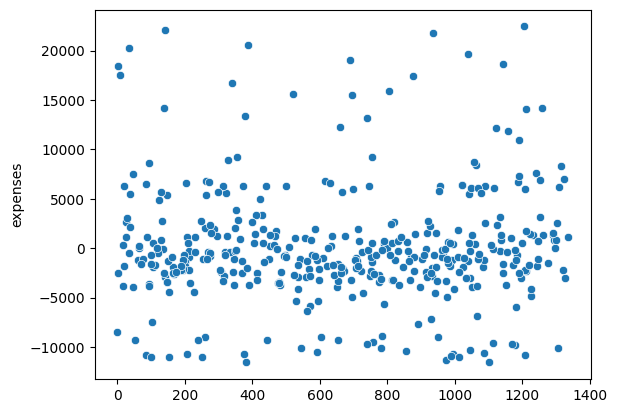

In [57]:
sns.scatterplot(( y_test - prediction ))

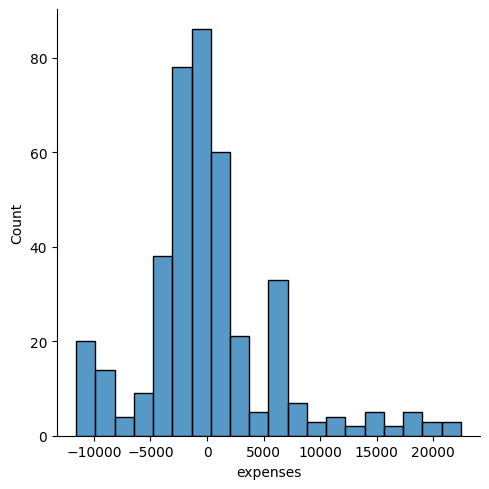

In [58]:
sns.displot(( y_test - prediction ), bins = 20)


# Step 5 : Model Evaluation

In [59]:
from sklearn import metrics

In [60]:
metrics.mean_absolute_error(y_test, prediction)
# closer to 0 is better. 

4041.1089698265605

In [61]:
metrics.mean_squared_error(y_test, prediction)

35312097.00921486

In [62]:
np.sqrt(metrics.mean_squared_error(y_test, prediction))
# closer to 0 is better. 

5942.39825400611

In [63]:
metrics.r2_score(y_test, prediction)

0.7293017109575524